## GridSearchCV para Regresión Ridge y Lasso, árboles de decisión y random forest

Ejemplo para el curso de Inteligencia Artificial. Adaptado del ejemplo de https://github.com/krishnaik06/Multiple-Linear-Regression.

## 1. Descripción del problema y objetivo

Una empresa desea estimar las ganancias (Profit) de una startup a partir de sus gastos en investigación y desarrollo (R&D Spend), administración (Administration), marketing (Marketing Spend) y su ubicación (State). Cada fila del conjunto de datos 50_Startups representa una empresa.

Objetivo: construir y comparar dos modelos de regresión para predecir Profit, árboles de decisión y random forest. Se evaluarán con datos que no se utilizaron para entrenarlos.

Las relaciones identificadas permiten hacer predicciones; no demuestran que un gasto cause directamente un cambio en las ganancias. El conjunto de datos es pequeño (50 empresas), por lo que sus resultados deben interpretarse con cautela.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

## 2.Inspección inicial del conjunto de datos

Antes de entrenar cualquier modelo se revisan las dimensiones, los tipos de datos, las estadísticas descriptivas y la calidad básica de los registros.

In [2]:
df = pd.read_csv("50_Startups.csv")
print("Dimensiones (filas, columnas):", df.shape)
df.info()

Dimensiones (filas, columnas): (50, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   R&D Spend        50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [3]:
df.head()

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
R&D Spend,50.0,NaN,NaN,NaN,73721.6156,45902.256482,0.0,39936.37,73051.08,101602.8,165349.2
Administration,50.0,NaN,NaN,NaN,121344.6396,28017.802755,51283.14,103730.875,122699.795,144842.18,182645.56
Marketing Spend,50.0,NaN,NaN,NaN,211025.0978,122290.310726,0.0,129300.1325,212716.24,299469.085,471784.1
State,50,3,New York,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Profit,50.0,NaN,NaN,NaN,112012.6392,40306.180338,14681.4,90138.9025,107978.19,139765.9775,192261.83


### 2.1 Valores faltantes y registros duplicados

Se inspeccionan los valores ausentes y las filas repetidas. Si se encuentran registros problemáticos, conviene revisar su origen antes de eliminarlos o reemplazarlos.

In [5]:
print("Valores faltantes por columna:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores faltantes por columna:
R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

Filas duplicadas: 0


El conjunto de datos contiene 50 registros de empresas y 5 variables. De estas, cuatro son numéricas (R&D Spend, Administration, Marketing Spend y Profit) y una es categórica (State), que presenta tres categorías: New York, California y Florida. La variable objetivo es Profit, mientras que las demás se utilizarán como variables predictoras.

El resultado de la función describe muestra diferencias importantes en las escalas y la dispersión de las variables numéricas. Por ejemplo, el gasto promedio en marketing es de aproximadamente 211.025, mientras que el gasto promedio en investigación y desarrollo es de 73.722. Las ganancias presentan un promedio de 112.013 y varían entre 14.681 y 192.262. También se observan valores mínimos de cero en los gastos de investigación y desarrollo y marketing, que conviene examinar posteriormente.

No se identificaron valores faltantes ni registros duplicados.

## 3. Exploración de la variable a predecir y las variables predictoras

La variable objetivo es Profit. Las variables numéricas predictoras son R&D Spend, Administration y Marketing Spend. State es categórica.

### 3.1 Distribución de la variable objetivo

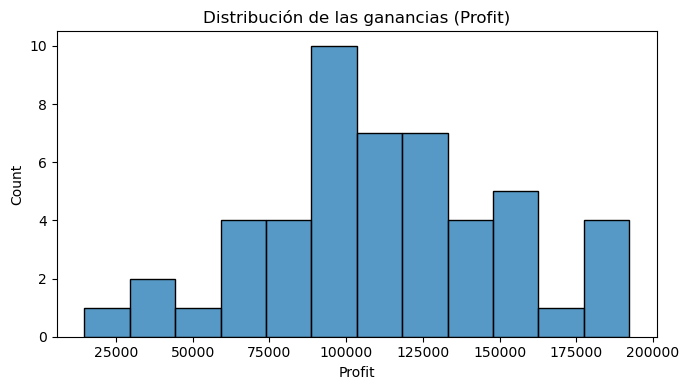

In [6]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Profit", bins=12)
plt.title("Distribución de las ganancias (Profit)")
plt.tight_layout()
plt.show()

### 3.2 Distribución de las variables predictoras

Para las variables numéricas se utilizan histogramas. Para State se utiliza un diagrama de barras con el número de empresas por estado.

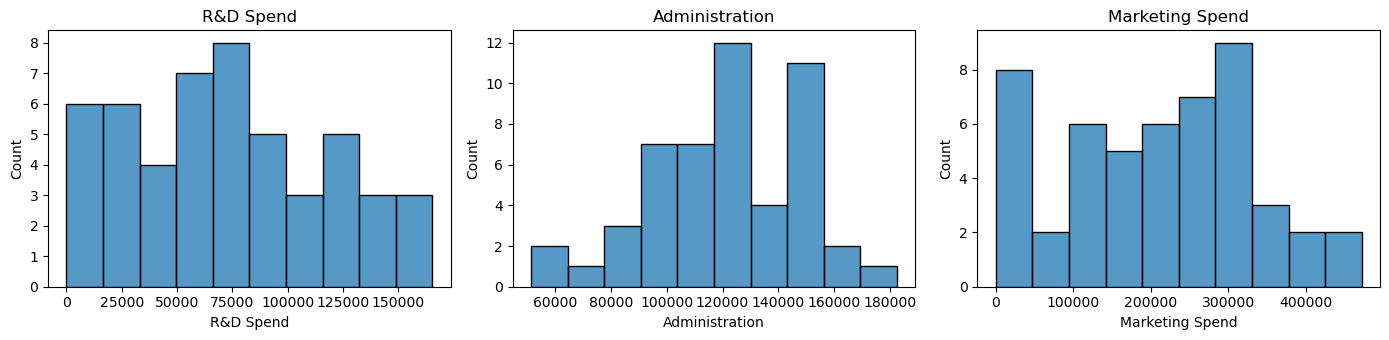

In [7]:
variables_numericas = ["R&D Spend", "Administration", "Marketing Spend"]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, variable in zip(axes, variables_numericas):
    sns.histplot(data=df, x=variable, bins=10, ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

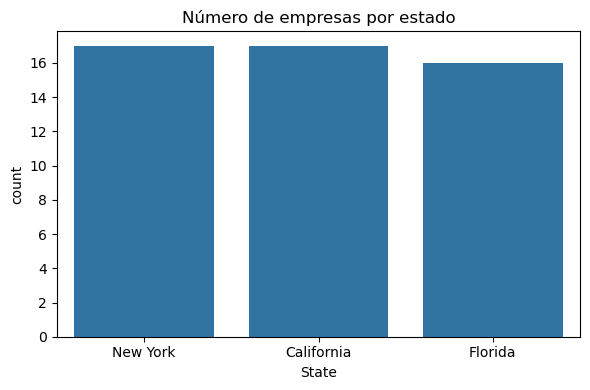

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="State")
plt.title("Número de empresas por estado")
plt.tight_layout()
plt.show()

### 3.3 Inspección de posibles valores atípicos

Los diagramas de cajas ayudan a detectar observaciones inusuales. Un valor señalado como atípico no es necesariamente incorrecto y no debe eliminarse automáticamente.

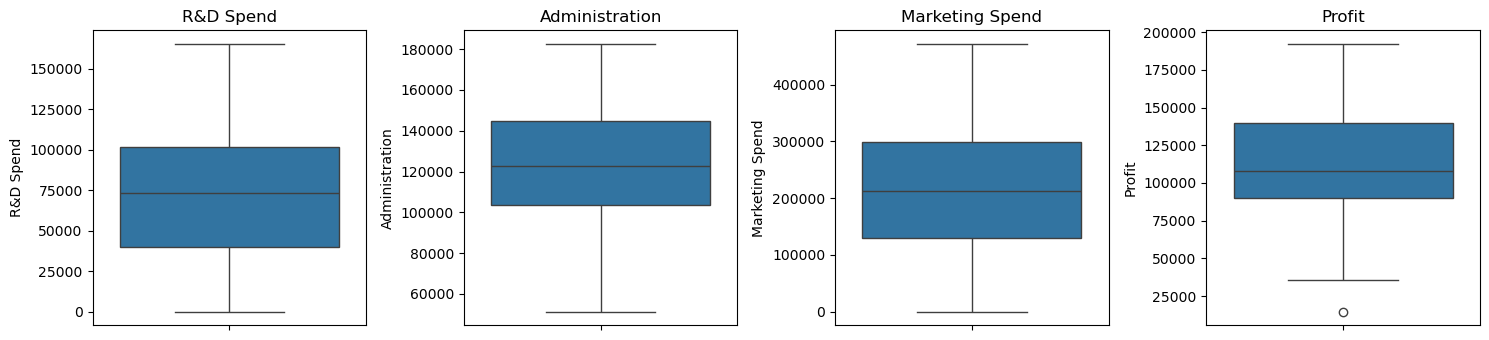

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, variable in zip(axes, variables_numericas + ["Profit"]):
    sns.boxplot(y=df[variable], ax=ax)
    ax.set_title(variable)
plt.tight_layout()
plt.show()

### 3.4 Correlación entre variables numéricas

Se utiliza la correlación de Pearson para explorar relaciones lineales, especialmente entre variables predictoras. Una correlación elevada entre predictores puede indicar multicolinealidad. La matriz sirve para explorar los datos, no para demostrar causalidad.

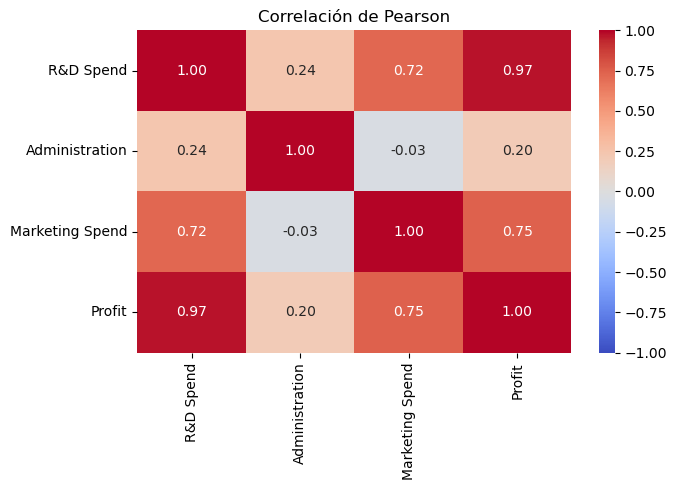

In [10]:
columnas_numericas = variables_numericas + ["Profit"]
correlaciones = df[columnas_numericas].corr(method="pearson")

plt.figure(figsize=(7, 5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Pearson")
plt.tight_layout()
plt.show()

Los histogramas muestran que las ganancias (Profit) se concentran principalmente entre 90.000 y 140.000, aunque existen empresas con ganancias considerablemente menores o mayores. Las variables predictoras presentan distribuciones diferentes: R&D Spend y Marketing Spend muestran una dispersión amplia, incluyendo empresas con gastos iguales o cercanos a cero, mientras que Administration presenta una mayor concentración alrededor de sus valores centrales.

Los diagramas de cajas permiten identificar un posible valor atípico en la variable Profit, correspondiente a una empresa con ganancias particularmente bajas. Sin embargo, esta observación no debe eliminarse sin verificar previamente si corresponde a un error o a un caso válido.

El análisis de correlación de Pearson muestra que R&D Spend presenta la relación lineal más fuerte con Profit (r = 0.97), seguida de Marketing Spend (r = 0.75). Por el contrario, Administration presenta una correlación positiva débil con las ganancias (r = 0.20). Esto sugiere que los gastos en investigación y desarrollo podrían tener una mayor capacidad predictiva, aunque la correlación por sí sola no permite establecer relaciones causales ni determinar la contribución de cada variable en un modelo múltiple.

## 4. Preparación de datos

Se separan las variables predictoras de la variable objetivo y se reservan el 20 % de las empresas para prueba. El conjunto de prueba no se utiliza para ajustar el escalamiento ni para seleccionar hiperparámetros.

En este ejemplo no se realizará reducción ni selección de características: solo hay tres predictores numéricos y una variable categórica, y no se ha encontrado una justificación suficiente para eliminar alguno. La matriz de correlación por sí sola no obliga a descartar predictores.

In [11]:
X = df[variables_numericas + ["State"]].copy()
y = df["Profit"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0
)
print("Ejemplos de entrenamiento:", len(X_train))
print("Ejemplos de prueba:", len(X_test))

Ejemplos de entrenamiento: 40
Ejemplos de prueba: 10


### 4.1 Codificación de la variable categórica State

Los modelos de regresión requieren valores numéricos. Se convierten los estados en variables indicadoras (0 o 1); se omite una categoría de referencia para evitar una redundancia perfecta con el intercepto. Se definen las categorías con el conjunto de entrenamiento y se utiliza la misma estructura de columnas al transformar la prueba.

In [12]:
X_train_cod = pd.get_dummies(X_train, columns=["State"], dtype=int)
X_test_cod = pd.get_dummies(X_test, columns=["State"], dtype=int)
X_test_cod = X_test_cod.reindex(columns=X_train_cod.columns, fill_value=0)

X_train_cod.head()
print(X_train_cod.head())

    R&D Spend  Administration  Marketing Spend  State_California  \
33   55493.95       103057.49        214634.81                 0   
35   46014.02        85047.44        205517.64                 0   
26   75328.87       144135.98        134050.07                 0   
34   46426.07       157693.92        210797.67                 1   
18   91749.16       114175.79        294919.57                 0   

    State_Florida  State_New York  
33              1               0  
35              0               1  
26              1               0  
34              0               0  
18              1               0  


### 4.2 Estandarización de las variables numéricas

StandardScaler resta la media y divide por la desviación estándar. Se ajusta únicamente con las observaciones de entrenamiento y luego se aplica a entrenamiento y prueba. Solo se escalan las tres variables de gasto; las columnas de State permanecen como 0 o 1. Esta estandarización es especialmente útil para comparar el efecto de la regularización de Ridge.

In [13]:
scaler = StandardScaler()
X_train_preparado = X_train_cod.copy()
X_test_preparado = X_test_cod.copy()

X_train_preparado[variables_numericas] = scaler.fit_transform(X_train_cod[variables_numericas])
X_test_preparado[variables_numericas] = scaler.transform(X_test_cod[variables_numericas])

X_train_preparado.head()

,R&D Spend,Administration,Marketing Spend,State_California,State_Florida,State_New York
33,-0.350065,-0.785471,0.101197,0,1,0
35,-0.555303,-1.481174,0.027350,0,0,1
26,0.079358,0.801334,-0.551521,0,1,0
34,-0.546382,1.325058,0.070117,1,0,0
18,0.434854,-0.355987,0.751485,0,1,0


## 5. Implementación base del modelo de regresión Ridge

In [14]:
def evaluar_modelo(valores_reales, predicciones):
    mae = mean_absolute_error(valores_reales, predicciones)
    rmse = np.sqrt(mean_squared_error(valores_reales, predicciones))

    rango = np.max(valores_reales) - np.min(valores_reales)

    return {"R2": r2_score(valores_reales, predicciones), "MAE": mae, "RMSE": rmse,
            "MAPE": mean_absolute_percentage_error(valores_reales, predicciones),
            "NMAE": mae / rango if rango > 0 else np.nan,
            "NRMSE": rmse / rango if rango > 0 else np.nan}

In [15]:
modelo_ridge = Ridge(alpha=1.0)
modelo_ridge.fit(X_train_preparado, y_train)

pred_ridge = modelo_ridge.predict(X_test_preparado)
metricas_ridge = evaluar_modelo(y_test, pred_ridge)
print(pd.Series(metricas_ridge).round(2))

R2          0.92
MAE      8018.49
RMSE     9947.36
MAPE        0.07
NMAE        0.07
NRMSE       0.09
dtype: float64


## 6. Implementación base del modelo de regresión Lasso

In [16]:
modelo_lasso = Lasso(alpha=1.0)
modelo_lasso.fit(X_train_preparado, y_train)

pred_lasso = modelo_lasso.predict(X_test_preparado)
metricas_lasso = evaluar_modelo(y_test, pred_lasso)
print(pd.Series(metricas_lasso).round(2))

R2          0.93
MAE      7511.54
RMSE     9134.15
MAPE        0.06
NMAE        0.07
NRMSE       0.08
dtype: float64


In [17]:
df_coef = pd.DataFrame({"Variable": X_train_preparado.columns, "Ridge": modelo_ridge.coef_, 
                        "Lasso": modelo_lasso.coef_})
print(df_coef.round(4))

           Variable       Ridge       Lasso
0         R&D Spend  33775.5633  35731.9999
1    Administration   1389.1078    848.8211
2   Marketing Spend   5747.0010   4514.7262
3  State_California    -32.0900   -163.1439
4     State_Florida  -1094.8754  -1118.8933
5    State_New York   1126.9654    531.3817


Al comparar los coeficientes obtenidos mediante Ridge y Lasso con alpha=1.0, se observa que ninguno de los coeficientes fue reducido a cero, o a un valor cercano de 0. 

# 7. Comparación de los resultados

En esta sección se comparan los resultados de la regresión Ridge y la regresión Lasso utilizando el conjunto de prueba.

In [18]:
# Comparación con la regresión lineal
comparacion = pd.DataFrame([metricas_ridge, metricas_lasso], index=["Regresión ridge", "Lasso"])
comparacion.round(2)

,R2,MAE,RMSE,MAPE,NMAE,NRMSE
Regresión ridge,0.92,8018.49,9947.36,0.07,0.07,0.09
Lasso,0.93,7511.54,9134.15,0.06,0.07,0.08


### 7.1 Valores reales frente a predichos

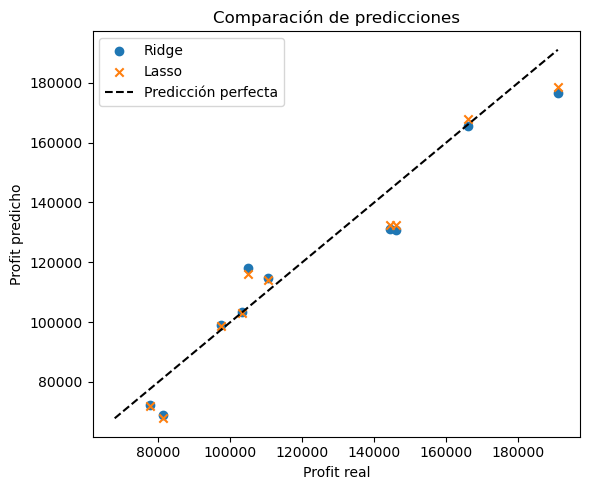

In [19]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_ridge, label="Ridge")
plt.scatter(y_test, pred_lasso, label="Lasso", marker="x")
limites = [min(y_test.min(), pred_ridge.min(), pred_lasso.min()),
           max(y_test.max(), pred_ridge.max(), pred_lasso.max())]
plt.plot(limites, limites, "k--", label="Predicción perfecta")
plt.xlabel("Profit real")
plt.ylabel("Profit predicho")
plt.title("Comparación de predicciones")
plt.legend()
plt.tight_layout()
plt.show()

En un modelo perfecto los puntos quedarían sobre la línea punteada. En la gráfica se puede observar que los resultados del modelo Ridge coinciden bastante con los resultados del modelo Lasso. En algunos casos ambos modelos generaron soluciones cercanas al valor real.

Ahora, se representan mediante gráficas de líneas los valores reales de Profit de las empresas del conjunto de prueba y los valores predichos por ambos modelos. El objetivo es observar visualmente qué tan próximas se encuentran las predicciones de ambos modelos a los valores reales e identificar aquellas observaciones donde presentan mayores errores.

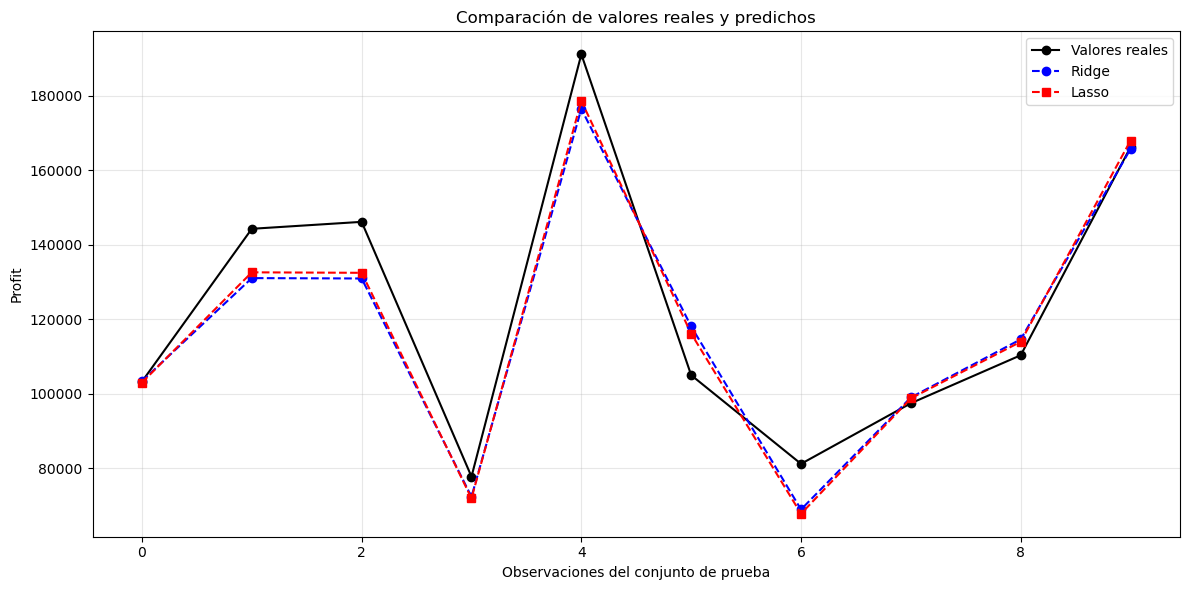

In [20]:
X = np.arange(len(y_test))
plt.figure(figsize=(12, 6))
plt.plot(X, np.array(y_test), 'k-o',label='Valores reales')
plt.plot(X, pred_ridge, 'b--o', label='Ridge')
plt.plot(X, pred_lasso, 'r--s',label='Lasso')
plt.xlabel('Observaciones del conjunto de prueba')
plt.ylabel('Profit')
plt.title('Comparación de valores reales y predichos')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Evalúemos si hay posible sobreajuste

In [21]:
pred_ridge_train = modelo_ridge.predict(X_train_preparado)
metricas_ridge_train = evaluar_modelo(y_train, pred_ridge_train)
print(pd.Series(metricas_ridge_train).round(2))

R2          0.95
MAE      6383.95
RMSE     9110.84
MAPE        0.12
NMAE        0.04
NRMSE       0.05
dtype: float64


In [22]:
pred_lasso_train = modelo_lasso.predict(X_train_preparado)
metricas_lasso_train = evaluar_modelo(y_train, pred_lasso_train)
print(pd.Series(metricas_lasso_train).round(2))

R2          0.95
MAE      6341.59
RMSE     9031.67
MAPE        0.12
NMAE        0.04
NRMSE       0.05
dtype: float64


In [23]:
tabla_metricas = pd.DataFrame({
    "Ridge - Entrenamiento": metricas_ridge_train,
    "Ridge - Prueba": metricas_ridge,
    "Lasso - Entrenamiento": metricas_lasso_train,
    "Lasso - Prueba": metricas_lasso
})

display(tabla_metricas.round(2))

,Ridge - Entrenamiento,Ridge - Prueba,Lasso - Entrenamiento,Lasso - Prueba
R2,0.95,0.92,0.95,0.93
MAE,6383.95,8018.49,6341.59,7511.54
RMSE,9110.84,9947.36,9031.67,9134.15
MAPE,0.12,0.07,0.12,0.06
NMAE,0.04,0.07,0.04,0.07
NRMSE,0.05,0.09,0.05,0.08


## 8. Implementación base de un modelo arbol de decisión

In [24]:
modelo_arbol1 = DecisionTreeRegressor(random_state=42)

modelo_arbol1.fit(X_train_preparado, y_train)
pred_arbol1 = modelo_arbol1.predict(X_test_preparado)

metricas_tree1 = evaluar_modelo(y_test, pred_arbol1)
print(pd.Series(metricas_tree1).round(2))

R2          0.98
MAE      4480.29
RMSE     5537.64
MAPE        0.04
NMAE        0.04
NRMSE       0.05
dtype: float64


Evaluemos enseguida si hubo sobreajuste:

In [25]:
pred_arbol1_train = modelo_arbol1.predict(X_train_preparado)
metricas_tree1_train = evaluar_modelo(y_train, pred_arbol1_train)
print(pd.Series(metricas_tree1_train).round(2))

R2       1.0
MAE      0.0
RMSE     0.0
MAPE     0.0
NMAE     0.0
NRMSE    0.0
dtype: float64


De acuerdo a estos resultados estamos frente a un caso de posible sobreajuste, corroboremos con una representación gráfica del árbol.

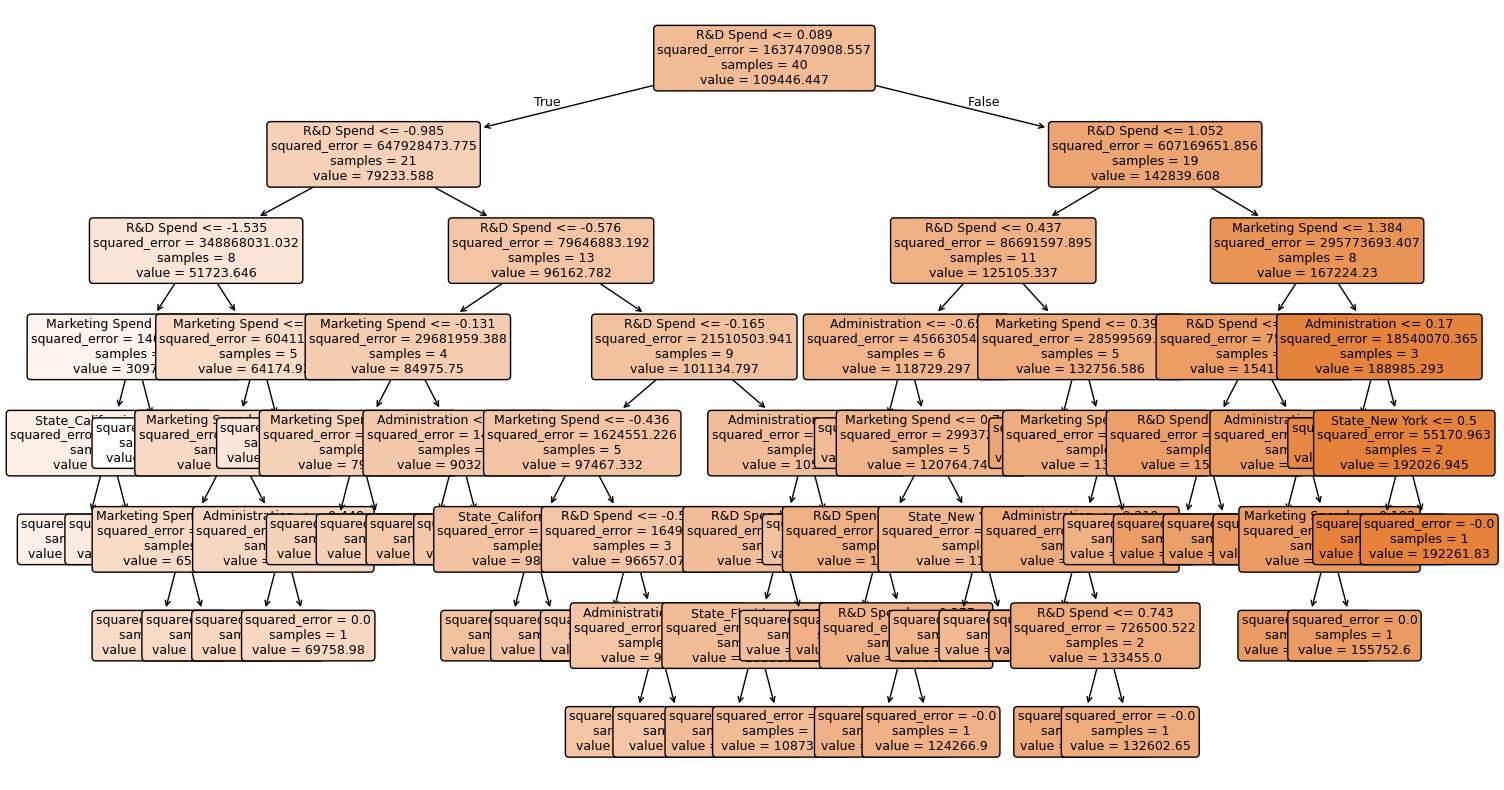

In [26]:
plt.figure(figsize=(18, 10))
plot_tree(modelo_arbol1, feature_names=X_train_preparado.columns, filled=True, rounded=True, fontsize=9)
plt.show()

In [27]:
es_hoja = modelo_arbol1.tree_.children_left == -1

# Número de observaciones en cada hoja
muestras_por_hoja = modelo_arbol1.tree_.n_node_samples[es_hoja]

# Cantidad de hojas con una sola observación
hojas_una_muestra = np.sum(muestras_por_hoja == 1)

print("Número total de hojas:", modelo_arbol1.get_n_leaves())
print("Hojas con una sola observación:", hojas_una_muestra)
print("Porcentaje:", round(100 * hojas_una_muestra / modelo_arbol1.get_n_leaves(), 2), "%")

Número total de hojas: 40
Hojas con una sola observación: 40
Porcentaje: 100.0 %


El 100% de las hojas del árbol contienen solo 1 ejemplo, lo cuál confirma el indicio de que el modelo está sobreajustado.

### 8.1 Utilicemos hiperparámetros para tratar de evitar el sobreajuste

In [28]:
modelo_arbol2 = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=42)

modelo_arbol2.fit(X_train_preparado, y_train)

pred_arbol2_train = modelo_arbol2.predict(X_train_preparado)
pred_arbol2 = modelo_arbol2.predict(X_test_preparado)

print("Resultados entrenamiento:")
print(pd.Series(evaluar_modelo(y_train, pred_arbol2_train)).round(2))

print("\nResultados prueba:")
print(pd.Series(evaluar_modelo(y_test, pred_arbol2)).round(2))

print("\nProfundidad:", modelo_arbol2.get_depth())
print("Número de hojas:", modelo_arbol2.get_n_leaves())

Resultados entrenamiento:
R2           0.91
MAE       9501.50
RMSE     12214.66
MAPE         0.15
NMAE         0.05
NRMSE        0.07
dtype: float64

Resultados prueba:
R2           0.85
MAE      10643.97
RMSE     13949.48
MAPE         0.10
NMAE         0.09
NRMSE        0.12
dtype: float64

Profundidad: 3
Número de hojas: 6


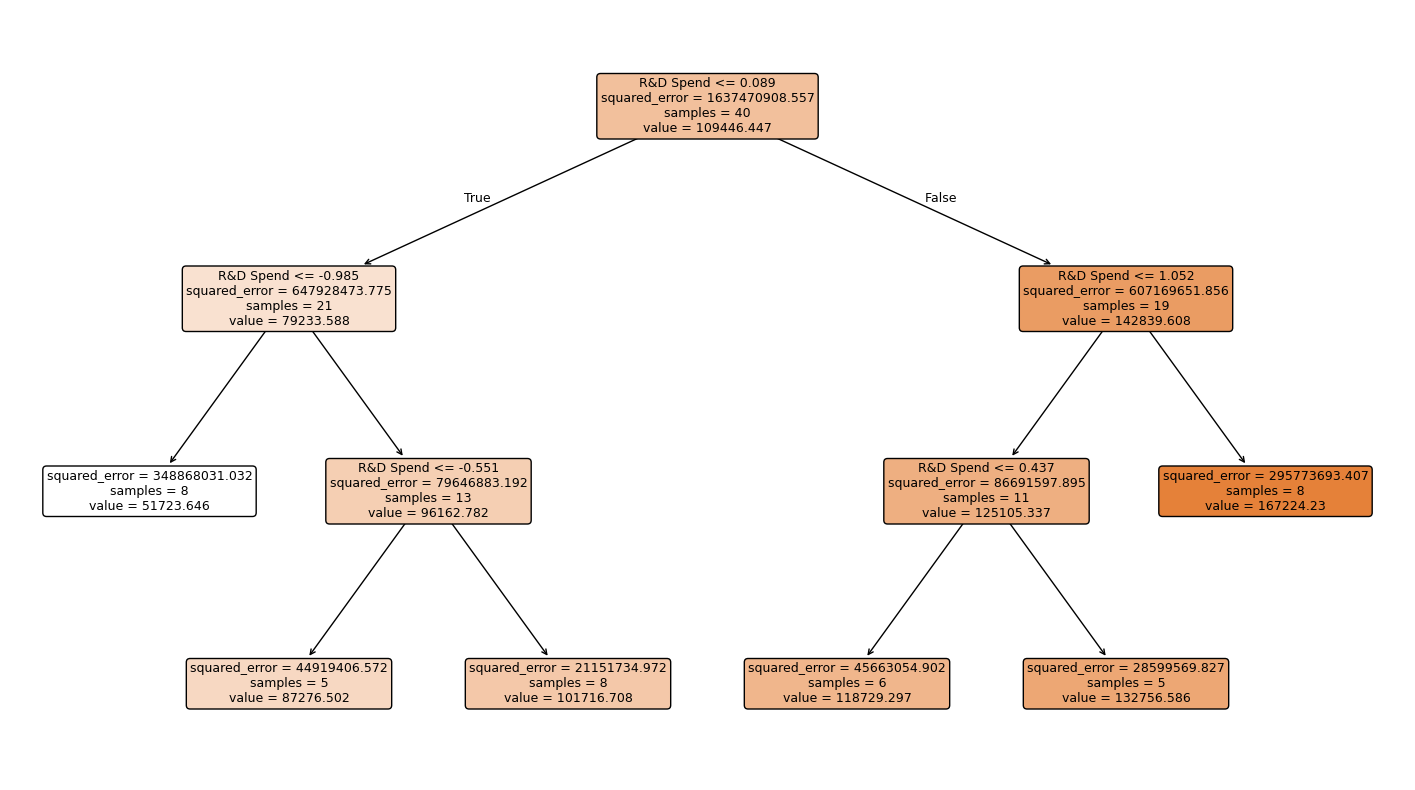

In [29]:
plt.figure(figsize=(18, 10))
plot_tree(modelo_arbol2, feature_names=X_train_preparado.columns, filled=True, rounded=True, fontsize=9)
plt.show()

## 9. Implementación base de un modelo Random Forest

In [30]:
modelo_rf1 = RandomForestRegressor(random_state=42)
modelo_rf1.fit(X_train_preparado, y_train)

pred_rf1 = modelo_rf1.predict(X_test_preparado)

metricas_rf1 = evaluar_modelo(y_test, pred_rf1)
print(pd.Series(metricas_rf1).round(2))

R2          0.96
MAE      5465.21
RMSE     6869.20
MAPE        0.05
NMAE        0.05
NRMSE       0.06
dtype: float64


Evalúemos si hay sobreajuste

In [31]:
pred_trainRF1 = modelo_rf1.predict(X_train_preparado)

metricas_trainRF1 = evaluar_modelo(y_train, pred_trainRF1)
print(pd.Series(metricas_trainRF1).round(2))

R2          0.99
MAE      3212.88
RMSE     4217.41
MAPE        0.06
NMAE        0.02
NRMSE       0.02
dtype: float64


In [32]:
def revisa_RF(modelo):
   resultados_arboles = []
   for i, arbol in enumerate(modelo.estimators_):

      # Identificar las hojas
      es_hoja = arbol.tree_.children_left == -1

      # Número de observaciones por hoja
      muestras_por_hoja = arbol.tree_.n_node_samples[es_hoja]

      # Porcentaje de hojas con una observación
      porcentaje = 100 * np.mean(muestras_por_hoja == 1)

      resultados_arboles.append({"Arbol": i + 1, "Profundidad": arbol.get_depth(),
                               "Numero_hojas": arbol.get_n_leaves(), "Porcentaje_hojas_1": porcentaje})
      df_arboles = pd.DataFrame(resultados_arboles)
   print(df_arboles.round(2))
   return df_arboles

In [33]:
df_arboles = revisa_RF(modelo_rf1)
print("Árboles con el 100% de hojas individuales:", (df_arboles["Porcentaje_hojas_1"] == 100).sum())

    Arbol  Profundidad  Numero_hojas  Porcentaje_hojas_1
0       1            7            27               100.0
1       2            8            23               100.0
2       3            8            29               100.0
3       4            7            28               100.0
4       5            7            23               100.0
..    ...          ...           ...                 ...
95     96            7            28               100.0
96     97            6            26               100.0
97     98            7            26               100.0
98     99            7            27               100.0
99    100            7            25               100.0

[100 rows x 4 columns]
Árboles con el 100% de hojas individuales: 100


Al parecer el modelo está sobreajustado vamos a utilizar algunos hiperparámetros tratando de evitar el sobreajueste

In [34]:
modelo_rf2 = RandomForestRegressor(n_estimators=100,  max_depth=10, min_samples_leaf=5, min_samples_split=10, random_state=42)

modelo_rf2.fit(X_train_preparado, y_train)

pred_rf2 = modelo_rf2.predict(X_test_preparado)
metricas_rf2 = evaluar_modelo(y_test, pred_rf2)
print(pd.Series(metricas_rf2).round(2))

R2           0.89
MAE       7721.32
RMSE     12094.45
MAPE         0.06
NMAE         0.07
NRMSE        0.11
dtype: float64


In [35]:
pred_trainRF2 = modelo_rf2.predict(X_train_preparado)

metricas_trainRF2 = evaluar_modelo(y_train, pred_trainRF2)
print(pd.Series(metricas_trainRF2).round(2))

R2           0.91
MAE       8429.60
RMSE     11797.97
MAPE         0.15
NMAE         0.05
NRMSE        0.07
dtype: float64


In [36]:
df_arboles2 = revisa_RF(modelo_rf2)
print("Árboles con el 100% de hojas individuales:", (df_arboles2["Porcentaje_hojas_1"] == 100).sum())

    Arbol  Profundidad  Numero_hojas  Porcentaje_hojas_1
0       1            2             4                 0.0
1       2            3             4                 0.0
2       3            3             4                 0.0
3       4            3             4                 0.0
4       5            3             4                 0.0
..    ...          ...           ...                 ...
95     96            3             5                 0.0
96     97            2             4                 0.0
97     98            2             4                 0.0
98     99            3             5                 0.0
99    100            3             4                 0.0

[100 rows x 4 columns]
Árboles con el 100% de hojas individuales: 0


# 10. Ajustemos hiperparámetros utilizando GridSearchCV

GridSearchCV prueba todas las combinaciones de hiperparámetros que se le indiquen y evalúa cada una mediante validación cruzada con 5 partes (cv=5), utilizando solo el conjunto de entrenamiento. Se elige la combinación con el menor RMSE promedio y luego ese modelo se evalúa con el conjunto de prueba.

Se utiliza RMSE porque está en las mismas unidades que Profit, lo que facilita su interpretación. Además, con solo 8 empresas en cada parte de la validación, el R2 puede variar mucho de una parte a otra, mientras que el RMSE es más estable.

GridSearchCV siempre busca el valor más alto de la métrica, por eso scikit-learn entrega el RMSE con signo negativo (neg_root_mean_squared_error). Para mostrarlo como un valor positivo se multiplica por -1.

In [37]:
from sklearn.model_selection import GridSearchCV

### 10.1 Regresión Ridge con GridSearchCV

El modelo base utilizó alpha=1.0. Se prueban valores de alpha desde una regularización muy débil (0.01) hasta una fuerte (100), con algunos valores adicionales cerca de 1 para revisar con más detalle esa región.

In [38]:
parametros_ridge1 = {"alpha": [0.01, 0.1, 0.5, 0.75, 1, 1.5, 2, 5, 10, 50, 100]}

grid_ridge1 = GridSearchCV(Ridge(), parametros_ridge1, cv=5, scoring="neg_root_mean_squared_error")
grid_ridge1.fit(X_train_preparado, y_train)

print("Mejores hiperparámetros:", grid_ridge1.best_params_)
print("RMSE en validación cruzada:", round(-grid_ridge1.best_score_, 2))

modelo_ridge_grid1 = grid_ridge1.best_estimator_
pred_ridge_grid1_train = modelo_ridge_grid1.predict(X_train_preparado)
pred_ridge_grid1 = modelo_ridge_grid1.predict(X_test_preparado)
metricas_ridge_grid1 = evaluar_modelo(y_test, pred_ridge_grid1)

print("\nResultados entrenamiento:")
print(pd.Series(evaluar_modelo(y_train, pred_ridge_grid1_train)).round(2))

print("\nResultados prueba:")
print(pd.Series(metricas_ridge_grid1).round(2))

Mejores hiperparámetros: {'alpha': 1}
RMSE en validación cruzada: 11625.8

Resultados entrenamiento:
R2          0.95
MAE      6383.95
RMSE     9110.84
MAPE        0.12
NMAE        0.04
NRMSE       0.05
dtype: float64

Resultados prueba:
R2          0.92
MAE      8018.49
RMSE     9947.36
MAPE        0.07
NMAE        0.07
NRMSE       0.09
dtype: float64


### 10.2 Regresión Lasso con GridSearchCV

Con alpha=1.0 Lasso no llevó ningún coeficiente a cero. Esto se debe a que Profit tiene valores muy grandes (cerca de 100.000), por lo que un alpha de 1 es muy pequeño. Por eso se prueban valores de alpha mucho mayores, con más valores entre 100 y 3000, que es la región donde se esperan los mejores resultados.

In [39]:
parametros_lasso1 = {"alpha": [1, 10, 100, 250, 500, 750, 1000, 1500, 2000, 3000, 5000, 10000]}

grid_lasso1 = GridSearchCV(Lasso(), parametros_lasso1, cv=5, scoring="neg_root_mean_squared_error")
grid_lasso1.fit(X_train_preparado, y_train)

print("Mejores hiperparámetros:", grid_lasso1.best_params_)
print("RMSE en validación cruzada:", round(-grid_lasso1.best_score_, 2))

modelo_lasso_grid1 = grid_lasso1.best_estimator_
pred_lasso_grid1_train = modelo_lasso_grid1.predict(X_train_preparado)
pred_lasso_grid1 = modelo_lasso_grid1.predict(X_test_preparado)
metricas_lasso_grid1 = evaluar_modelo(y_test, pred_lasso_grid1)

print("\nResultados entrenamiento:")
print(pd.Series(evaluar_modelo(y_train, pred_lasso_grid1_train)).round(2))

print("\nResultados prueba:")
print(pd.Series(metricas_lasso_grid1).round(2))

Mejores hiperparámetros: {'alpha': 1000}
RMSE en validación cruzada: 9967.51

Resultados entrenamiento:
R2          0.95
MAE      6422.29
RMSE     9142.19
MAPE        0.12
NMAE        0.04
NRMSE       0.05
dtype: float64

Resultados prueba:
R2          0.95
MAE      6772.77
RMSE     8307.72
MAPE        0.06
NMAE        0.06
NRMSE       0.07
dtype: float64


Comparemos los coeficientes del Lasso base con los del Lasso encontrado por GridSearchCV.

In [40]:
df_coef_grid = pd.DataFrame({"Variable": X_train_preparado.columns, "Lasso base": modelo_lasso.coef_,
                             "Lasso GridSearchCV": modelo_lasso_grid1.coef_})
print(df_coef_grid.round(4))

           Variable  Lasso base  Lasso GridSearchCV
0         R&D Spend  35731.9999          35849.7795
1    Administration    848.8211              0.0000
2   Marketing Spend   4514.7262           3438.9405
3  State_California   -163.1439             -0.0000
4     State_Florida  -1118.8933             -0.0000
5    State_New York    531.3817              0.0000


### 10.3 Árbol de decisión con GridSearchCV

El árbol base memorizó el conjunto de entrenamiento, y el árbol con max_depth=8 y min_samples_leaf=5 redujo el sobreajuste pero empeoró en prueba. Se prueban varias combinaciones de profundidad máxima, mínimo de ejemplos por hoja y mínimo de ejemplos para dividir un nodo.

In [41]:
parametros_arbol1 = {"max_depth": [2, 3, 4, 5, 6, 8, None],
                     "min_samples_leaf": [1, 2, 3, 4, 5],
                     "min_samples_split": [2, 5, 10]}

grid_arbol1 = GridSearchCV(DecisionTreeRegressor(random_state=42), parametros_arbol1, cv=5, scoring="neg_root_mean_squared_error")
grid_arbol1.fit(X_train_preparado, y_train)

print("Mejores hiperparámetros:", grid_arbol1.best_params_)
print("RMSE en validación cruzada:", round(-grid_arbol1.best_score_, 2))

modelo_arbol_grid1 = grid_arbol1.best_estimator_
pred_arbol_grid1_train = modelo_arbol_grid1.predict(X_train_preparado)
pred_arbol_grid1 = modelo_arbol_grid1.predict(X_test_preparado)
metricas_arbol_grid1 = evaluar_modelo(y_test, pred_arbol_grid1)

print("\nResultados entrenamiento:")
print(pd.Series(evaluar_modelo(y_train, pred_arbol_grid1_train)).round(2))

print("\nResultados prueba:")
print(pd.Series(metricas_arbol_grid1).round(2))

print("\nProfundidad:", modelo_arbol_grid1.get_depth())
print("Número de hojas:", modelo_arbol_grid1.get_n_leaves())

Mejores hiperparámetros: {'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 2}
RMSE en validación cruzada: 12776.19

Resultados entrenamiento:
R2          0.99
MAE      3138.07
RMSE     4598.16
MAPE        0.06
NMAE        0.02
NRMSE       0.03
dtype: float64

Resultados prueba:
R2          0.94
MAE      6021.45
RMSE     8966.79
MAPE        0.05
NMAE        0.05
NRMSE       0.08
dtype: float64

Profundidad: 5
Número de hojas: 16


### 10.4 Random Forest con GridSearchCV

Los árboles del Random Forest base tenían todas sus hojas con una sola empresa, y el segundo modelo generó árboles muy pequeños. Se prueban valores intermedios de profundidad y de ejemplos por hoja, el número de árboles y max_features, que indica la proporción de variables que se consideran en cada división. Esta búsqueda entrena muchos modelos, por lo que puede tardar uno o dos minutos.

In [42]:
parametros_rf1 = {"n_estimators": [100, 200],
                  "max_depth": [3, 4, 5, 7, None],
                  "min_samples_leaf": [1, 2, 4],
                  "max_features": [0.5, 0.75, 1.0]}

grid_rf1 = GridSearchCV(RandomForestRegressor(random_state=42), parametros_rf1, cv=5, scoring="neg_root_mean_squared_error")
grid_rf1.fit(X_train_preparado, y_train)

print("Mejores hiperparámetros:", grid_rf1.best_params_)
print("RMSE en validación cruzada:", round(-grid_rf1.best_score_, 2))

modelo_rf_grid1 = grid_rf1.best_estimator_
pred_rf_grid1_train = modelo_rf_grid1.predict(X_train_preparado)
pred_rf_grid1 = modelo_rf_grid1.predict(X_test_preparado)
metricas_rf_grid1 = evaluar_modelo(y_test, pred_rf_grid1)

print("\nResultados entrenamiento:")
print(pd.Series(evaluar_modelo(y_train, pred_rf_grid1_train)).round(2))

print("\nResultados prueba:")
print(pd.Series(metricas_rf_grid1).round(2))

Mejores hiperparámetros: {'max_depth': 5, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 100}
RMSE en validación cruzada: 12536.81

Resultados entrenamiento:
R2          0.99
MAE      3330.17
RMSE     4229.32
MAPE        0.06
NMAE        0.02
NRMSE       0.02
dtype: float64

Resultados prueba:
R2          0.96
MAE      5605.17
RMSE     7136.38
MAPE        0.05
NMAE        0.05
NRMSE       0.06
dtype: float64


In [43]:
df_arboles_grid1 = revisa_RF(modelo_rf_grid1)
print("Árboles con el 100% de hojas individuales:", (df_arboles_grid1["Porcentaje_hojas_1"] == 100).sum())

    Arbol  Profundidad  Numero_hojas  Porcentaje_hojas_1
0       1            5            20               75.00
1       2            5            16               81.25
2       3            5            18               72.22
3       4            5            21               80.95
4       5            5            18               83.33
..    ...          ...           ...                 ...
95     96            5            21               71.43
96     97            5            23               86.96
97     98            5            21               80.95
98     99            5            19               73.68
99    100            5            21               90.48

[100 rows x 4 columns]
Árboles con el 100% de hojas individuales: 0


### 10.5 Comparación de los modelos en el conjunto de prueba

In [44]:
comparacion_grid1 = pd.DataFrame([metricas_ridge, metricas_ridge_grid1,
                                  metricas_lasso, metricas_lasso_grid1,
                                  metricas_tree1, metricas_arbol_grid1,
                                  metricas_rf2, metricas_rf_grid1],
                                 index=["Ridge base", "Ridge GridSearchCV",
                                        "Lasso base", "Lasso GridSearchCV",
                                        "Árbol base", "Árbol GridSearchCV",
                                        "Random Forest 2", "Random Forest GridSearchCV"])
comparacion_grid1.round(2)

,R2,MAE,RMSE,MAPE,NMAE,NRMSE
Ridge base,0.92,8018.49,9947.36,0.07,0.07,0.09
Ridge GridSearchCV,0.92,8018.49,9947.36,0.07,0.07,0.09
Lasso base,0.93,7511.54,9134.15,0.06,0.07,0.08
Lasso GridSearchCV,0.95,6772.77,8307.72,0.06,0.06,0.07
Árbol base,0.98,4480.29,5537.64,0.04,0.04,0.05
Árbol GridSearchCV,0.94,6021.45,8966.79,0.05,0.05,0.08
Random Forest 2,0.89,7721.32,12094.45,0.06,0.07,0.11
Random Forest GridSearchCV,0.96,5605.17,7136.38,0.05,0.05,0.06


Considerando el desempeño en el conjunto de prueba, el modelo con mejores resultados fue el árbol de decisión base, con un R2 de 0.98 y un RMSE de 5.538, seguido de Random Forest con GridSearchCV (R2 de 0.96 y RMSE de 7.136) y Lasso con GridSearchCV (R2 de 0.95 y RMSE de 8.308).

Este resultado es llamativo, porque el árbol base memorizó el conjunto de entrenamiento (R2 de 1.0, con una sola empresa en cada hoja). La rejilla de GridSearchCV incluía exactamente esa configuración (max_depth=None, min_samples_leaf=1 y min_samples_split=2), pero en la validación cruzada obtuvo un RMSE de 15.217 y quedó en el puesto 33 de 105 combinaciones. Es decir, al evaluarlo con distintas partes del conjunto de entrenamiento el árbol sin restricciones generalizó peor, mientras que con las 10 empresas de prueba obtuvo muy buenos resultados. Esto sugiere que las empresas de prueba son muy parecidas a algunas de entrenamiento, y que con otra división de los datos el resultado podría ser diferente.

El árbol de GridSearchCV tiene profundidad 5 y 16 hojas. En prueba obtuvo un R2 de 0.94 y un RMSE de 8.967, por debajo del árbol base, aunque es un modelo más pequeño y fue el que mejor se comportó en la validación cruzada.

Random Forest con GridSearchCV mejoró frente al Random Forest 2: el R2 subió de 0.89 a 0.96 y el RMSE bajó de 12.094 a 7.136. Sin embargo, no superó al Random Forest base de la sección 9, que obtuvo un R2 de 0.96 y un RMSE de 6.869. Sus árboles tienen profundidad 5 y ninguno tiene el 100 % de sus hojas con una sola empresa, aunque en promedio el 81 % de sus hojas todavía tienen una sola empresa y el R2 en entrenamiento (0.99) sigue siendo mayor que en prueba.

Lasso con GridSearchCV mejoró frente al Lasso base: el R2 pasó de 0.93 a 0.95 y el RMSE bajó de 9.134 a 8.308. Además, utiliza solo R&D Spend y Marketing Spend, tiene el mismo R2 en entrenamiento y en prueba (0.95) y es el modelo más sencillo de interpretar entre los mejores. En Ridge, GridSearchCV eligió el mismo valor de alpha del modelo base (alpha=1), por lo que los resultados no cambiaron (R2 de 0.92 y RMSE de 9.947).

En casi todos los casos, los mejores hiperparámetros quedaron dentro de los rangos probados y no en sus extremos, lo que indica que los rangos de búsqueda fueron suficientemente amplios. Las excepciones son min_samples_split=2 en el árbol y min_samples_leaf=1 y max_features=1.0 en Random Forest, que son los valores límite posibles de esos hiperparámetros, y n_estimators=100 en Random Forest, que es el menor valor probado, aunque su diferencia con 200 árboles fue muy pequeña.

En conclusión, en el conjunto de prueba la búsqueda de hiperparámetros mejoró los resultados de Lasso, no cambió los de Ridge y no superó a los modelos base de árbol de decisión y Random Forest. El mejor resultado lo obtuvo el árbol de decisión base, aunque la validación cruzada indica que este modelo está sobreajustado y que su buen desempeño puede deberse a las empresas que quedaron en el conjunto de prueba. Como el conjunto de prueba tiene solo 10 empresas, una sola empresa mal predicha puede cambiar el orden de los modelos, por lo que las diferencias entre los mejores modelos deben interpretarse con cautela.